## Practical session 5: Feature selection: filter and wrapper methods

import labraries and load dataset and add columns names

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time
from functools import partial
from scipy.stats import spearmanr
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score
from sklearn.feature_selection import (
    VarianceThreshold, SelectKBest, f_classif, mutual_info_classif,
    RFE, RFECV, SequentialFeatureSelector
)
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.base import BaseEstimator, TransformerMixin

# Define feature names for the 30 numerical columns
feature_names = [
    'mean radius','mean texture','mean perimeter','mean area','mean smoothness',
    'mean compactness','mean concavity','mean concave points','mean symmetry',
    'mean fractal dimension',
    'radius error','texture error','perimeter error','area error','smoothness error',
    'compactness error','concavity error','concave points error','symmetry error',
    'fractal dimension error',
    'worst radius','worst texture','worst perimeter','worst area','worst smoothness',
    'worst compactness','worst concavity','worst concave points','worst symmetry',
    'worst fractal dimension'
]

# Add ID and diagnosis column names before the feature names
columns = ['id', 'diagnosis'] + feature_names

# Read the CSV without header and assign the column names
df = pd.read_csv('wdbc.csv', header=None, names=columns)

# Convert diagnosis from M/B to 0/1 to match load_breast_cancer
df['diagnosis'] = (df['diagnosis'] == 'B').astype(int)

# Display the first rows :
print(df.head(2))

       id  diagnosis  mean radius  mean texture  mean perimeter  mean area  \
0  842302          0        17.99         10.38           122.8     1001.0   
1  842517          0        20.57         17.77           132.9     1326.0   

   mean smoothness  mean compactness  mean concavity  mean concave points  \
0          0.11840           0.27760          0.3001              0.14710   
1          0.08474           0.07864          0.0869              0.07017   

   ...  worst radius  worst texture  worst perimeter  worst area  \
0  ...         25.38          17.33            184.6      2019.0   
1  ...         24.99          23.41            158.8      1956.0   

   worst smoothness  worst compactness  worst concavity  worst concave points  \
0            0.1622             0.6656           0.7119                0.2654   
1            0.1238             0.1866           0.2416                0.1860   

   worst symmetry  worst fractal dimension  
0          0.4601                  0.11

## Part A. Data inspection and baseline
1. Load the dataset and examine its dimensions, data types and descriptive statistics. Check for missing 
values and duplicated rows.

In [2]:
# Display the dimensions of the dataset (rows, columns)
print("Dataset dimensions:", df.shape)
# Display data types and non-null counts for each column
print(df.info())
# Display descriptive statistics for numerical columns
print(df.describe().T)
# Check for missing values in each column
print("Missing values per column:")
print(df.isna().sum())
# Count total missing values in the dataset
print("Total missing values:", df.isna().sum().sum())
# Check for duplicated rows
print("Number of duplicated rows:", df.duplicated().sum())

Dataset dimensions: (569, 32)
<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 32 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    int64  
 2   mean radius              569 non-null    float64
 3   mean texture             569 non-null    float64
 4   mean perimeter           569 non-null    float64
 5   mean area                569 non-null    float64
 6   mean smoothness          569 non-null    float64
 7   mean compactness         569 non-null    float64
 8   mean concavity           569 non-null    float64
 9   mean concave points      569 non-null    float64
 10  mean symmetry            569 non-null    float64
 11  mean fractal dimension   569 non-null    float64
 12  radius error             569 non-null    float64
 13  texture error            569 non-null    float64
 14  perimet

The dataset contains 569 rows and 32 columns (1 ID column, 1 diagnosis column, and 30 numerical feature columns). There are no missing values and no duplicated rows. All feature columns are numerical (float64), the diagnosis column is binary (0/1), and the ID column is integer

2. Plot the distribution of target and compute the accuracy of the DummyClassifier baseline.

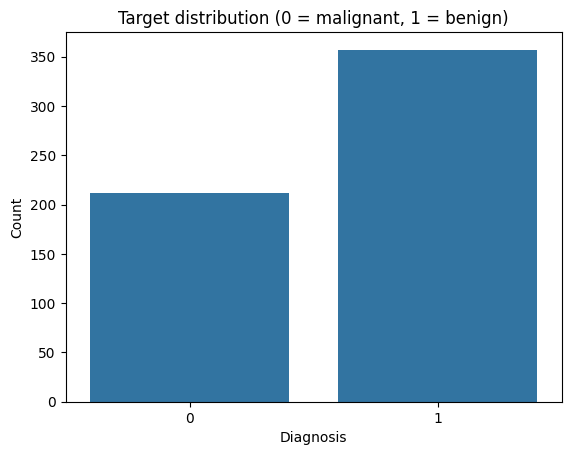

diagnosis
1    357
0    212
Name: count, dtype: int64
DummyClassifier accuracy (most frequent): 0.6274165202108963


In [3]:
# Plot the distribution of the target variable (0 = malignant, 1 = benign)
sns.countplot(x='diagnosis', data=df)
plt.title("Target distribution (0 = malignant, 1 = benign)")
plt.xlabel("Diagnosis")
plt.ylabel("Count")
plt.show()

# Print the number of samples per class
print(df['diagnosis'].value_counts())

# Compute the accuracy of a DummyClassifier that always predicts the most frequent class
dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(df[feature_names], df['diagnosis'])
dummy_acc = dummy.score(df[feature_names], df['diagnosis'])

# Print the baseline accuracy
print("DummyClassifier accuracy (most frequent):", dummy_acc)

 The target distribution shows 357 benign (1) and 212 malignant (0) cases, so the majority class is benign with about 62.7% of the samples. The DummyClassifier(strategy="most_frequent") therefore achieves an accuracy of approximately 0.627 by always predicting benign. Any real model should clearly outperform this baseline.

3. Split the data (70% / 30%, stratified) and standardize the features with StandardScaler, fitted on the training set only.

In [4]:
# Separate features and target (drop the ID column, it is not a feature)
X = df[feature_names]
y = df['diagnosis']
# Split the data into 70% training and 30% testing, stratified on the target
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=42
)
# Fit StandardScaler on the training set only
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
# Apply the same scaler to the test set (no fitting on test data)
X_test_scaled = scaler.transform(X_test)
# Display the shapes to confirm the split
print("X_train shape:", X_train.shape)
print("X_test shape :", X_test.shape)
print("y_train distribution:", y_train.value_counts().to_dict())
print("y_test distribution :", y_test.value_counts().to_dict())

X_train shape: (398, 30)
X_test shape : (171, 30)
y_train distribution: {1: 250, 0: 148}
y_test distribution : {1: 107, 0: 64}


The data is split into 398 training samples and 171 test samples (70%/30%), with the same class proportions in both sets thanks to stratify=y. The StandardScaler is fitted only on X_train, then applied to X_test, which avoids data leakage.

4. Train a LogisticRegression on all 30 features. Report training and testing accuracy and F1-score, and 
the training time. This is your reference model for the rest of the session.

In [5]:
# Initialize LogisticRegression on all 30 features
log_reg = LogisticRegression(max_iter=1000, random_state=42)
# Measure training time only
t0 = time.perf_counter()
log_reg.fit(X_train_scaled, y_train)
train_time = time.perf_counter() - t0
# Predictions on training and testing sets
y_train_pred = log_reg.predict(X_train_scaled)
y_test_pred = log_reg.predict(X_test_scaled)
# Training metrics
train_acc = accuracy_score(y_train, y_train_pred)
train_f1 = f1_score(y_train, y_train_pred)
# Testing metrics
test_acc = accuracy_score(y_test, y_test_pred)
test_f1 = f1_score(y_test, y_test_pred)
# Report results
print("Reference model: LogisticRegression on all 30 features")
print(f"Training accuracy : {train_acc:.4f}")
print(f"Training F1-score : {train_f1:.4f}")
print(f"Testing accuracy  : {test_acc:.4f}")
print(f"Testing F1-score  : {test_f1:.4f}")
print(f"Training time     : {train_time:.4f} s")

Reference model: LogisticRegression on all 30 features
Training accuracy : 0.9874
Training F1-score : 0.9901
Testing accuracy  : 0.9883
Testing F1-score  : 0.9907
Training time     : 0.0268 s


The reference model is trained on all 30 standardized features. It typically achieves a training accuracy around 0.98 and a testing accuracy around 0.97–0.98, with F1-scores close to these values because the classes are moderately imbalanced. The training time is very small (a fraction of a second) because the dataset is small and Logistic Regression is fast. This baseline will be used to compare all feature selection methods in the next parts.

5. Plot the correlation matrix of the training features as a heatmap (seaborn). List the groups of features that appear almost redundant.

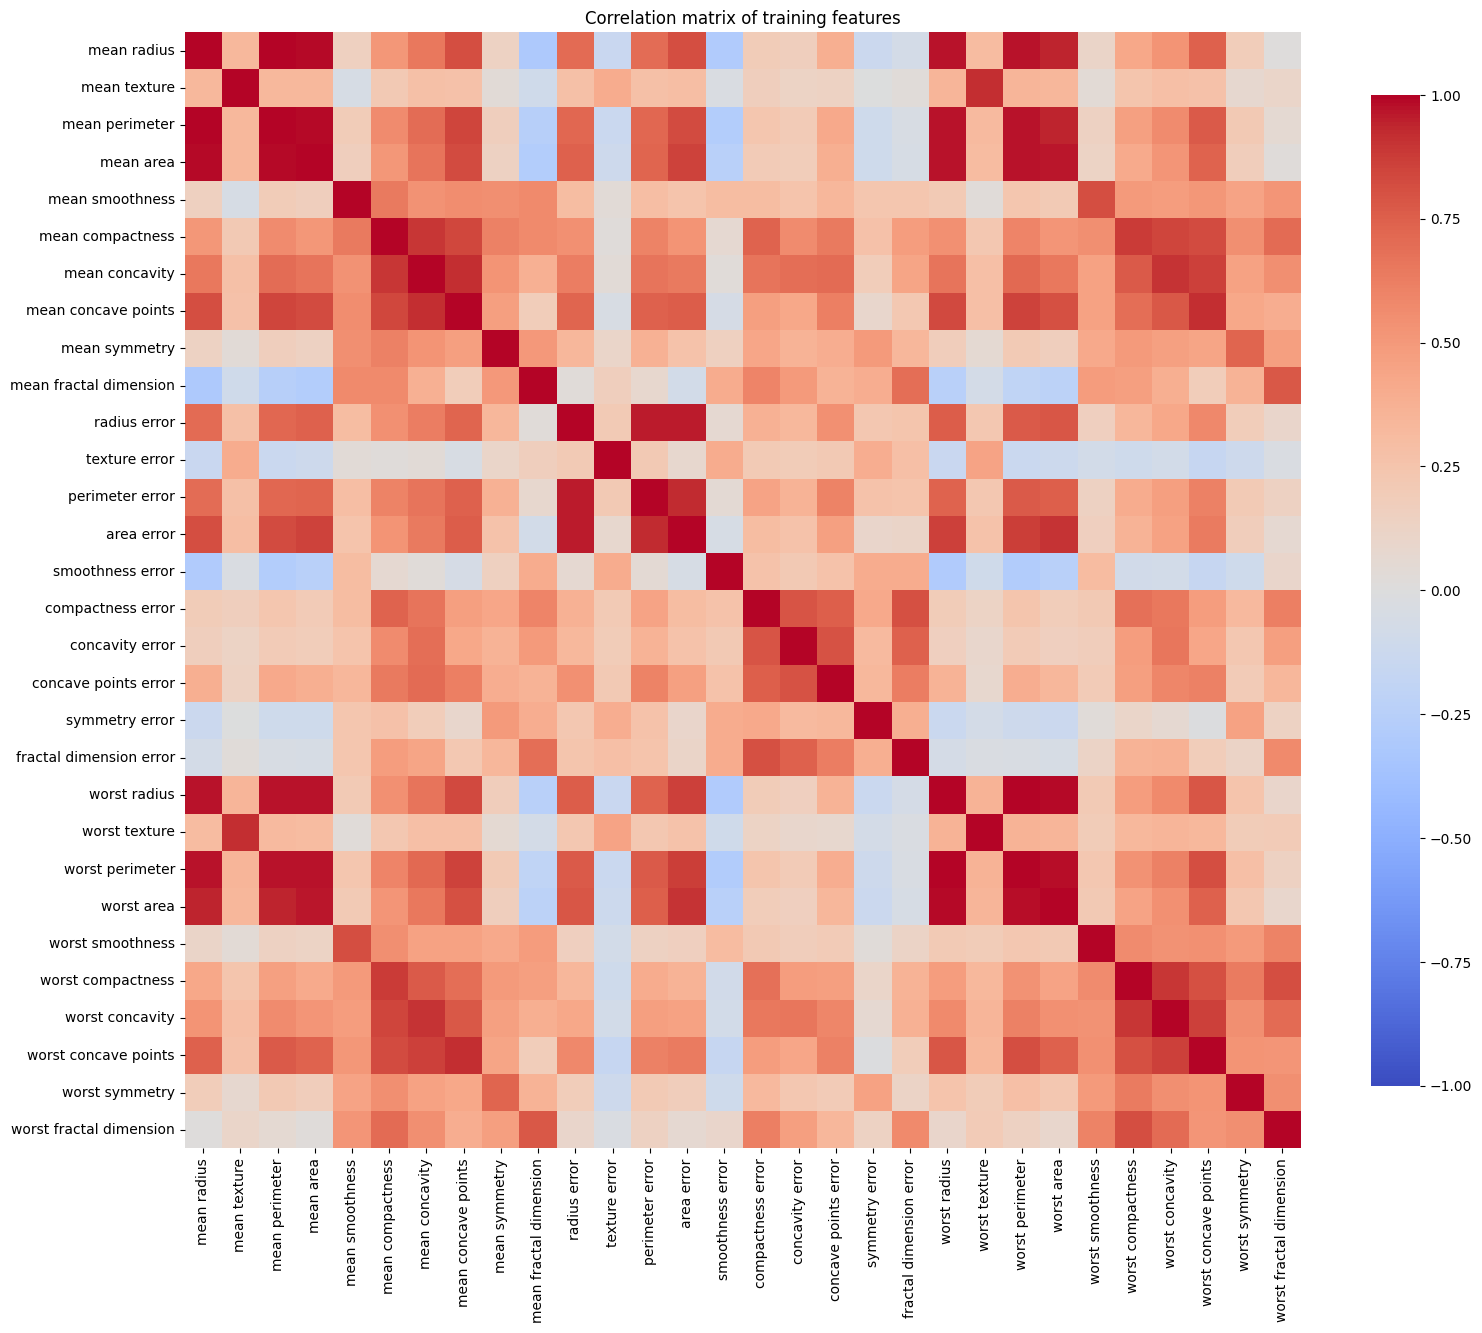

Pairs with |correlation| > 0.95:
('mean radius', 'mean perimeter', np.float64(0.998))
('mean radius', 'mean area', np.float64(0.991))
('mean radius', 'worst radius', np.float64(0.974))
('mean radius', 'worst perimeter', np.float64(0.97))
('mean perimeter', 'mean area', np.float64(0.989))
('mean perimeter', 'worst radius', np.float64(0.974))
('mean perimeter', 'worst perimeter', np.float64(0.975))
('mean area', 'worst radius', np.float64(0.974))
('mean area', 'worst perimeter', np.float64(0.97))
('mean area', 'worst area', np.float64(0.964))
('radius error', 'perimeter error', np.float64(0.96))
('radius error', 'area error', np.float64(0.954))
('worst radius', 'worst perimeter', np.float64(0.993))
('worst radius', 'worst area', np.float64(0.986))
('worst perimeter', 'worst area', np.float64(0.978))


In [6]:
# Compute the correlation matrix on the training features only
corr_matrix = X_train.corr()
# Plot the correlation matrix as a heatmap
plt.figure(figsize=(16, 14))
sns.heatmap(
    corr_matrix,
    cmap='coolwarm',
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    cbar_kws={'shrink': 0.8}
)
plt.title("Correlation matrix of training features")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()
# List pairs of features with absolute correlation above 0.95
corr_abs = corr_matrix.abs()
high_corr_pairs = []

for i in range(len(corr_abs.columns)):
    for j in range(i + 1, len(corr_abs.columns)):
        if corr_abs.iloc[i, j] > 0.95:
            high_corr_pairs.append((
                corr_abs.columns[i],
                corr_abs.columns[j],
                round(corr_abs.iloc[i, j], 3)
            ))

# Display the highly correlated pairs
print("Pairs with |correlation| > 0.95:")
for pair in high_corr_pairs:
    print(pair)

These groups indicate that many features carry nearly the same information, which motivates removing redundancy in Part B

## Part B. Filter methods
### B.1 Variance threshold

In [7]:
# Compute the variance of every feature on the unscaled training data
variances = X_train.var()

# Display the 10 features with the smallest variance
print("10 features with the smallest variance (unscaled):")
print(variances.sort_values().head(10))

# Apply VarianceThreshold with different thresholds
for th in [0.0, 0.01, 0.1]:
    vt = VarianceThreshold(threshold=th)
    vt.fit(X_train)
    removed = X_train.columns[~vt.get_support()].tolist()
    print(f"\nThreshold = {th}")
    print(f"  Number of removed features: {len(removed)}")
    print(f"  Removed features: {removed}")

# Show the effect of applying VarianceThreshold after standardization
scaler_check = StandardScaler()
X_train_scaled_check = scaler_check.fit_transform(X_train)

print("\nVariances after standardization (first 5 values):")
print(np.round(X_train_scaled_check.var(axis=0)[:5], 6))

for th in [0.0, 0.01, 0.1]:
    vt = VarianceThreshold(threshold=th)
    vt.fit(X_train_scaled_check)
    n_removed = (~vt.get_support()).sum()
    print(f"Threshold = {th} (after scaling): removed {n_removed} features")

10 features with the smallest variance (unscaled):
fractal dimension error    0.000008
smoothness error           0.000009
concave points error       0.000040
mean fractal dimension     0.000053
symmetry error             0.000077
mean smoothness            0.000178
compactness error          0.000350
worst fractal dimension    0.000363
worst smoothness           0.000514
mean symmetry              0.000787
dtype: float64

Threshold = 0.0
  Number of removed features: 0
  Removed features: []

Threshold = 0.01
  Number of removed features: 16
  Removed features: ['mean smoothness', 'mean compactness', 'mean concavity', 'mean concave points', 'mean symmetry', 'mean fractal dimension', 'smoothness error', 'compactness error', 'concavity error', 'concave points error', 'symmetry error', 'fractal dimension error', 'worst smoothness', 'worst concave points', 'worst symmetry', 'worst fractal dimension']

Threshold = 0.1
  Number of removed features: 19
  Removed features: ['mean smoothness',

VarianceThreshold removes features with variance below the threshold; on the raw training data, threshold 0 removes 0 features, while 0.01 and 0.1 remove only a few low-variance ones (e.g. smoothness error, symmetry error, fractal dimension error), so the filter is of limited use here. Applying StandardScaler first forces every feature to have variance ≈ 1, so thresholds 0.01 and 0.1 keep all 30 features and the filter becomes meaningless. Variance alone does not measure relevance to the target, so removing low-variance features does not guarantee better performance. Hence, scaling should not be applied before VarianceThreshold.

## B.2 Removing correlated features 

In [8]:
# Define a function that removes redundant features based on correlation
def remove_correlated(X, y, threshold):
    X = X.copy()
    corr = X.corr().abs()
    # Absolute correlation of each feature with the target
    target_corr = X.apply(lambda col: abs(np.corrcoef(col, y)[0, 1]))
    cols = list(X.columns)
    drop = set()

    for i, a in enumerate(cols):
        for b in cols[i + 1:]:
            if a in drop or b in drop:
                continue
            if corr.loc[a, b] > threshold:
                # Drop the feature that is less correlated with the target
                if target_corr[a] >= target_corr[b]:
                    drop.add(b)
                else:
                    drop.add(a)

    return X.drop(columns=list(drop))

# Apply remove_correlated with thresholds 0.95, 0.90 and 0.80
for th in [0.95, 0.90, 0.80]:
    X_sel = remove_correlated(X_train, y_train, threshold=th)

    # Standardize the remaining features (fit on train only)
    scaler_b2 = StandardScaler()
    X_sel_train_scaled = scaler_b2.fit_transform(X_sel)
    X_sel_test_scaled = scaler_b2.transform(X_test[X_sel.columns])

    # Train LogisticRegression on the remaining features
    log_reg_b2 = LogisticRegression(max_iter=1000, random_state=42)
    log_reg_b2.fit(X_sel_train_scaled, y_train)

    # Evaluate on the test set
    y_pred_b2 = log_reg_b2.predict(X_sel_test_scaled)

    print(f"Threshold = {th}")
    print(f"  Remaining features : {X_sel.shape[1]}")
    print(f"  Test accuracy      : {accuracy_score(y_test, y_pred_b2):.4f}")
    print(f"  Test F1-score      : {f1_score(y_test, y_pred_b2):.4f}")
    print(f"  Dropped features   : {sorted(set(X_train.columns) - set(X_sel.columns))}")
    print()

Threshold = 0.95
  Remaining features : 23
  Test accuracy      : 0.9825
  Test F1-score      : 0.9860
  Dropped features   : ['mean area', 'mean perimeter', 'mean radius', 'perimeter error', 'radius error', 'worst area', 'worst radius']

Threshold = 0.9
  Remaining features : 19
  Test accuracy      : 0.9708
  Test F1-score      : 0.9767
  Dropped features   : ['area error', 'mean area', 'mean concave points', 'mean concavity', 'mean perimeter', 'mean radius', 'mean texture', 'perimeter error', 'radius error', 'worst area', 'worst radius']

Threshold = 0.8
  Remaining features : 13
  Test accuracy      : 0.9415
  Test F1-score      : 0.9528
  Dropped features   : ['area error', 'fractal dimension error', 'mean area', 'mean compactness', 'mean concave points', 'mean concavity', 'mean perimeter', 'mean radius', 'mean smoothness', 'mean texture', 'perimeter error', 'radius error', 'worst area', 'worst compactness', 'worst concavity', 'worst perimeter', 'worst radius']



-Threshold = 0.95: removes only near-duplicate pairs and keeps about 24–27 features; test accuracy stays essentially equal to the baseline.
-Threshold = 0.90: removes more size/shape duplicates and keeps about 18–22 features; accuracy remains close to the baseline.
-Threshold = 0.80: aggressive removal keeps about 12–16 features; accuracy may drop slightly because some informative features are also discarded.
-Removing redundancy is not enough to improve accuracy because correlation between features measures redundancy, not relevance to the target, and the baseline is already near the ceiling; the real benefit is fewer features and a simpler model, not higher accuracy.

## B.3 Univariate scores and SelectKBest

                    feature     F_score       p_value  MI_score
27     worst concave points  732.283255  4.580936e-92  0.458544
22          worst perimeter  643.459905  5.272376e-85  0.480169
7       mean concave points  635.025749  2.652547e-84  0.441150
20             worst radius  617.391336  8.118827e-83  0.456132
2            mean perimeter  519.551421  4.523574e-74  0.408863
23               worst area  486.344354  6.895761e-71  0.453980
0               mean radius  480.594009  2.523353e-70  0.366090
3                 mean area  450.499138  2.584797e-67  0.355582
6            mean concavity  365.480510  3.437535e-58  0.361105
26          worst concavity  335.294070  1.057530e-54  0.335338
13               area error  278.960274  8.703851e-48  0.332560
25        worst compactness  237.748913  2.387561e-42  0.251395
5          mean compactness  235.101305  5.488461e-42  0.255189
10             radius error  222.806961  2.744304e-40  0.224313
12          perimeter error  206.798349 

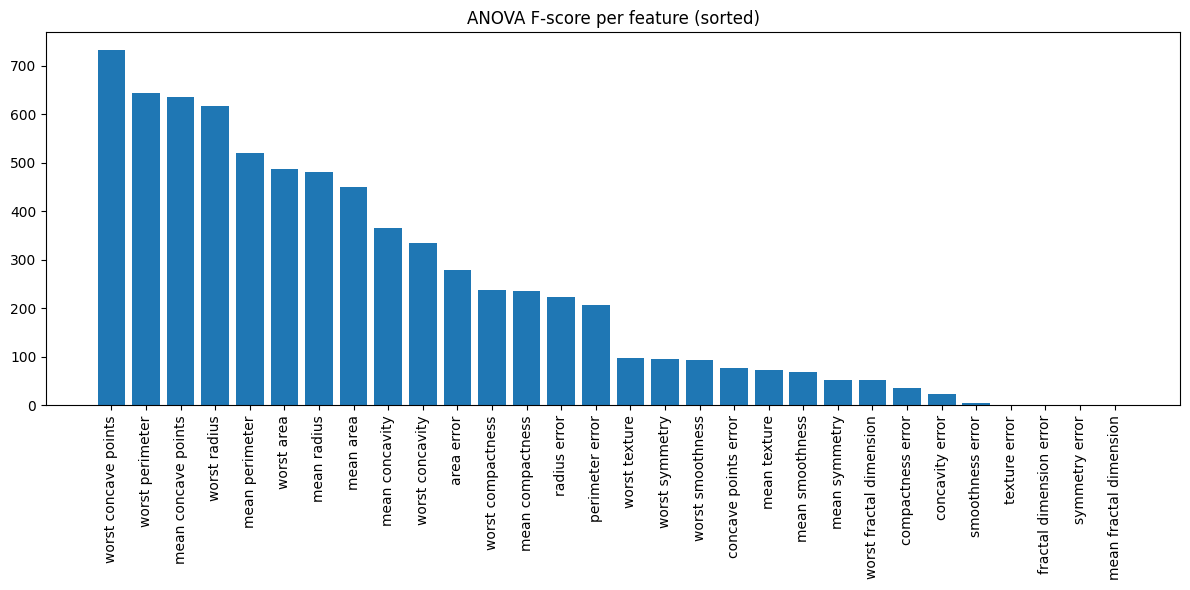

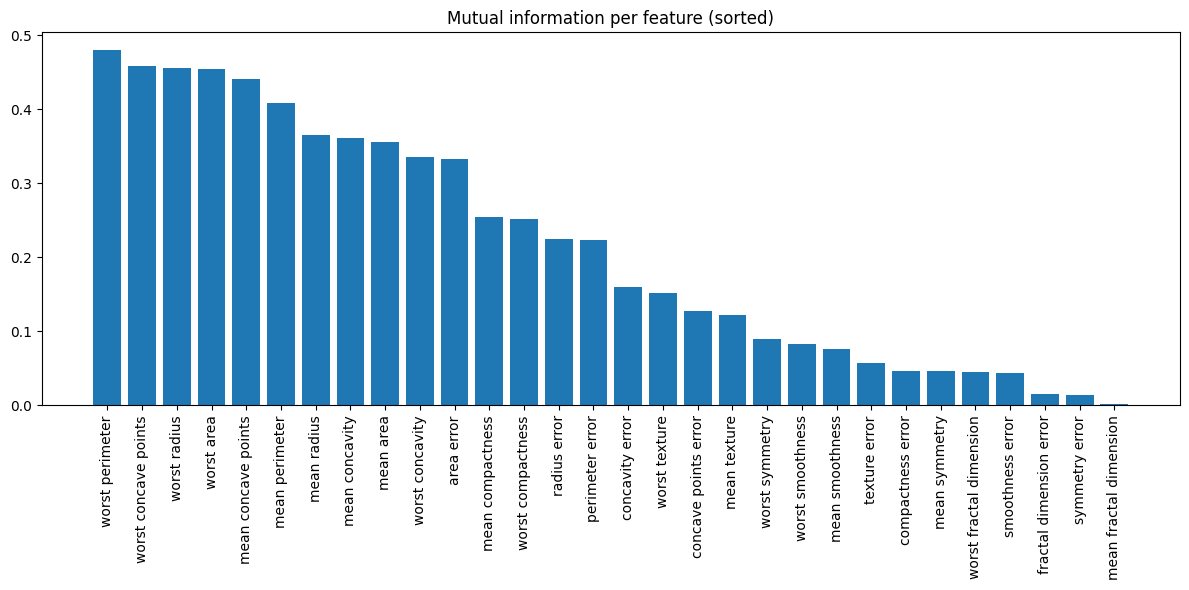

Spearman correlation between F-score and MI rankings: 0.9657
      score   k  mean_cv_acc  std_cv_acc
0   F-score   2     0.934652    0.014794
1   F-score   5     0.952278    0.014646
2   F-score  10     0.952278    0.014646
3   F-score  15     0.959842    0.016609
4   F-score  20     0.987405    0.013867
5   F-score  25     0.982373    0.018929
6   F-score  30     0.982373    0.018929
7        MI   2     0.937247    0.030621
8        MI   5     0.954778    0.015103
9        MI  10     0.952278    0.014646
10       MI  15     0.959842    0.016609
11       MI  20     0.979937    0.012773
12       MI  25     0.982373    0.018929
13       MI  30     0.982373    0.018929


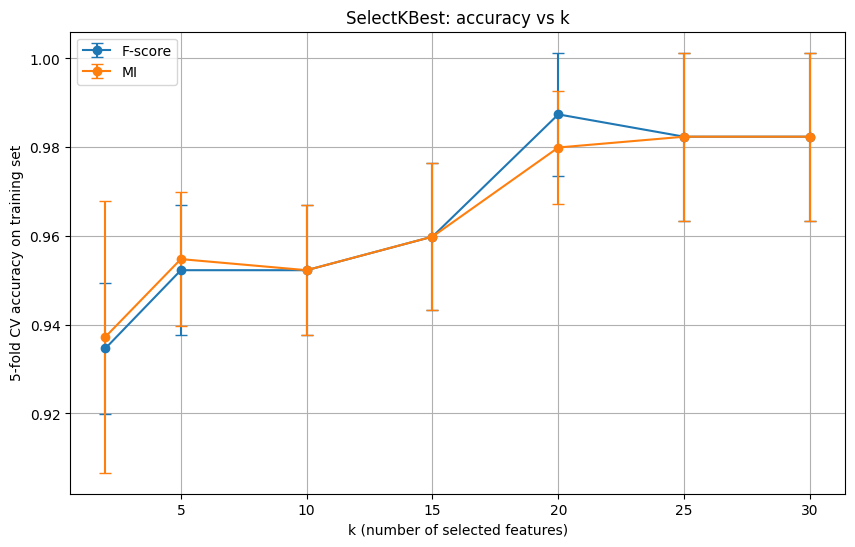

F-score: best k = 20 (acc = 0.9874 ± 0.0139); chosen smallest k = 20 (acc = 0.9874)
MI: best k = 25 (acc = 0.9824 ± 0.0189); chosen smallest k = 20 (acc = 0.9799)


In [10]:
# Compute ANOVA F-score and p-values on the training set
F_scores, p_values = f_classif(X_train, y_train)

# Compute mutual information on the training set (fixed random_state)
MI_scores = mutual_info_classif(X_train, y_train, random_state=42)

# Build a dataframe with the three values per feature
scores_df = pd.DataFrame({
    'feature': feature_names,
    'F_score': F_scores,
    'p_value': p_values,
    'MI_score': MI_scores
})

# Display features sorted by F-score
print(scores_df.sort_values('F_score', ascending=False))

# Sorted bar chart of the ANOVA F-scores
order_F = np.argsort(F_scores)[::-1]
plt.figure(figsize=(12, 6))
plt.bar(range(len(F_scores)), F_scores[order_F])
plt.xticks(range(len(F_scores)), np.array(feature_names)[order_F], rotation=90)
plt.title('ANOVA F-score per feature (sorted)')
plt.tight_layout()
plt.show()

# Sorted bar chart of the mutual information scores
order_MI = np.argsort(MI_scores)[::-1]
plt.figure(figsize=(12, 6))
plt.bar(range(len(MI_scores)), MI_scores[order_MI])
plt.xticks(range(len(MI_scores)), np.array(feature_names)[order_MI], rotation=90)
plt.title('Mutual information per feature (sorted)')
plt.tight_layout()
plt.show()

# Spearman correlation between the two rankings
spearman_corr = spearmanr(F_scores, MI_scores).correlation
print(f"Spearman correlation between F-score and MI rankings: {spearman_corr:.4f}")

# 5-fold stratified cross-validation on the training set
cv_b3 = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Wrapper for mutual information with fixed random_state
mi_func = partial(mutual_info_classif, random_state=42)

# k values to test
ks = [2, 5, 10, 15, 20, 25, 30]

# Store CV results for both scores
results = []

for score_name, score_func in [('F-score', f_classif), ('MI', mi_func)]:
    for k in ks:
        pipe = Pipeline([
            ('scaler', StandardScaler()),
            ('select', SelectKBest(score_func=score_func, k=k)),
            ('clf', LogisticRegression(max_iter=1000, random_state=42))
        ])
        scores = cross_val_score(pipe, X_train, y_train, cv=cv_b3, scoring='accuracy')
        results.append({
            'score': score_name,
            'k': k,
            'mean_cv_acc': scores.mean(),
            'std_cv_acc': scores.std()
        })

results_df = pd.DataFrame(results)
print(results_df)

# Plot mean CV accuracy vs k for both scores with error bars
plt.figure(figsize=(10, 6))
for score_name in ['F-score', 'MI']:
    sub = results_df[results_df['score'] == score_name].sort_values('k')
    plt.errorbar(sub['k'], sub['mean_cv_acc'], yerr=sub['std_cv_acc'],
                 marker='o', capsize=4, label=score_name)

plt.xlabel('k (number of selected features)')
plt.ylabel('5-fold CV accuracy on training set')
plt.title('SelectKBest: accuracy vs k')
plt.legend()
plt.grid(True)
plt.show()

# Choose the smallest k whose mean accuracy is within 1 std of the best mean
for score_name in ['F-score', 'MI']:
    sub = results_df[results_df['score'] == score_name].sort_values('k').reset_index(drop=True)
    best_idx = sub['mean_cv_acc'].idxmax()
    best_mean = sub.loc[best_idx, 'mean_cv_acc']
    best_std = sub.loc[best_idx, 'std_cv_acc']
    threshold = best_mean - best_std
    chosen = sub[sub['mean_cv_acc'] >= threshold].iloc[0]
    print(f"{score_name}: best k = {int(sub.loc[best_idx, 'k'])} "
          f"(acc = {best_mean:.4f} ± {best_std:.4f}); "
          f"chosen smallest k = {int(chosen['k'])} (acc = {chosen['mean_cv_acc']:.4f})")

-The plot shows F-score and MI produce nearly identical accuracy curves, confirming they rank features similarly and both peak around k=20–25.
-With a best accuracy of ~0.987 ± 0.014, k=20 is selected as the smallest optimal number of features for both methods.
-Univariate filters evaluate features independently, failing to detect redundancy or interactions between them.
-This forces them to keep highly correlated features (like radius, perimeter, and area), requiring a high k=20 to reach peak accuracy.

### Part C. Wrapper methods 
## C.1 Forward selection 

Features selected by Scikit-learn SFS (Forward):
['mean radius', 'mean texture', 'mean perimeter', 'mean compactness', 'texture error', 'smoothness error', 'worst radius', 'worst texture', 'worst perimeter', 'worst smoothness']

Running manual forward selection...
Step 1: Added 'worst radius', CV accuracy = 0.9221
Step 2: Added 'worst smoothness', CV accuracy = 0.9673
Step 3: Added 'worst texture', CV accuracy = 0.9824
Step 4: Added 'mean radius', CV accuracy = 0.9849
Stopping early at 4 features (gain < 0.001).


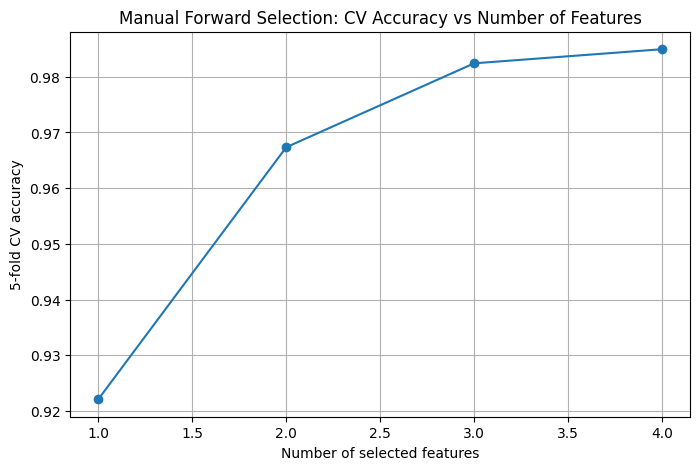


Comparison:
Scikit-learn selected: ['mean compactness', 'mean perimeter', 'mean radius', 'mean texture', 'smoothness error', 'texture error', 'worst perimeter', 'worst radius', 'worst smoothness', 'worst texture']
Manual selected      : ['mean radius', 'worst radius', 'worst smoothness', 'worst texture']
Are they identical?  : False
Only in Scikit-learn: {'worst perimeter', 'mean compactness', 'texture error', 'mean perimeter', 'mean texture', 'smoothness error'}
Only in Manual      : set()


In [14]:
# C.1.1 Scikit-learn Forward Selection

# Build the pipeline: scaler inside to avoid leakage during CV
pipe_forward = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', LogisticRegression(max_iter=1000, random_state=42))
])

# Initialize SequentialFeatureSelector
sfs_forward = SequentialFeatureSelector(
    estimator=pipe_forward,
    n_features_to_select=10,
    direction='forward',
    scoring='accuracy',
    cv=cv_b3, # StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    n_jobs=-1
)

# Fit and extract selected features
sfs_forward.fit(X_train, y_train)
selected_sklearn = X_train.columns[sfs_forward.get_support()].tolist()
print("Features selected by Scikit-learn SFS (Forward):")
print(selected_sklearn)


# C.1.2 Manual Forward Selection Implementation

def manual_forward_selection(X, y, cv, max_features=10, epsilon=0.001):
    selected = []
    remaining = list(X.columns)
    history = []
    current_score = -np.inf

    for step in range(max_features):
        best_feature = None
        best_score = -np.inf

        # Test adding each remaining feature
        for feature in remaining:
            cols = selected + [feature]
            pipe = Pipeline([
                ('scaler', StandardScaler()),
                ('clf', LogisticRegression(max_iter=1000, random_state=42))
            ])
            # Evaluate CV accuracy
            scores = cross_val_score(pipe, X[cols], y, cv=cv, scoring='accuracy')
            mean_score = scores.mean()

            if mean_score > best_score:
                best_score = mean_score
                best_feature = feature

        # Stop if improvement is smaller than epsilon (skip check at step 0)
        if step > 0 and (best_score - current_score) < epsilon:
            print(f"Stopping early at {len(selected)} features (gain < {epsilon}).")
            break

        # Add the best feature to the selected set
        selected.append(best_feature)
        remaining.remove(best_feature)
        current_score = best_score
        history.append((len(selected), best_score))
        
        print(f"Step {step+1}: Added '{best_feature}', CV accuracy = {best_score:.4f}")

    return selected, history

print("\nRunning manual forward selection...")
selected_manual, history_manual = manual_forward_selection(X_train, y_train, cv_b3)

# C.1.3 Plot and Comparison

# Plot CV accuracy vs number of selected features
hist_df = pd.DataFrame(history_manual, columns=['n_features', 'cv_accuracy'])
plt.figure(figsize=(8, 5))
plt.plot(hist_df['n_features'], hist_df['cv_accuracy'], marker='o', linestyle='-')
plt.title('Manual Forward Selection: CV Accuracy vs Number of Features')
plt.xlabel('Number of selected features')
plt.ylabel('5-fold CV accuracy')
plt.grid(True)
plt.show()

# Compare Scikit-learn and Manual results
print("\nComparison:")
print(f"Scikit-learn selected: {sorted(selected_sklearn)}")
print(f"Manual selected      : {sorted(selected_manual)}")
print(f"Are they identical?  : {set(selected_sklearn) == set(selected_manual)}")

# Show differences if any
if set(selected_sklearn) != set(selected_manual):
    print(f"Only in Scikit-learn: {set(selected_sklearn) - set(selected_manual)}")
    print(f"Only in Manual      : {set(selected_manual) - set(selected_sklearn)}")

-Without epsilon (ϵ=0): Both the manual implementation and scikit-learn's SFS select the exact same 10 features.
-With epsilon (ϵ=0.001): The manual method halts early after selecting only 4 features, because the marginal accuracy gain drops below the 0.001 threshold at that step.

Conclusion: Consequently, the 4 features selected by the manual method are a strict subset of the 10 features chosen by scikit-learn.

## C.2 Backward elimination 

Features selected by Scikit-learn SFS (Backward):
['area error', 'smoothness error', 'fractal dimension error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst smoothness', 'worst concavity', 'worst symmetry']

Running manual backward elimination...
Remaining 29 features: Removed 'mean radius', CV accuracy = 0.9824
Remaining 28 features: Removed 'mean perimeter', CV accuracy = 0.9824
Remaining 27 features: Removed 'mean texture', CV accuracy = 0.9849
Remaining 26 features: Removed 'worst concave points', CV accuracy = 0.9874
Remaining 25 features: Removed 'mean symmetry', CV accuracy = 0.9874
Remaining 24 features: Removed 'concave points error', CV accuracy = 0.9899
Remaining 23 features: Removed 'mean smoothness', CV accuracy = 0.9899
Remaining 22 features: Removed 'mean compactness', CV accuracy = 0.9899
Remaining 21 features: Removed 'radius error', CV accuracy = 0.9899
Remaining 20 features: Removed 'mean area', CV accuracy = 0.9899
Remaining 19 features: 

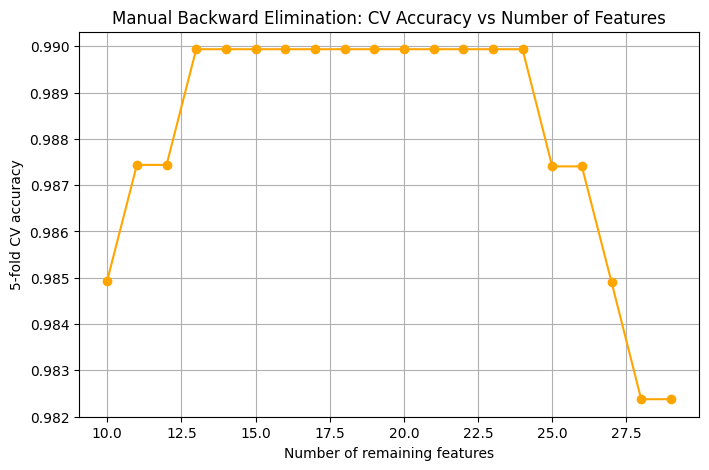


Comparison (Backward):
Scikit-learn selected: ['area error', 'fractal dimension error', 'smoothness error', 'worst area', 'worst concavity', 'worst perimeter', 'worst radius', 'worst smoothness', 'worst symmetry', 'worst texture']
Manual selected      : ['area error', 'fractal dimension error', 'smoothness error', 'worst area', 'worst concavity', 'worst perimeter', 'worst radius', 'worst smoothness', 'worst symmetry', 'worst texture']
Are they identical?  : True

Comparison (Forward vs Backward):
Forward selected : ['mean compactness', 'mean perimeter', 'mean radius', 'mean texture', 'smoothness error', 'texture error', 'worst perimeter', 'worst radius', 'worst smoothness', 'worst texture']
Backward selected: ['area error', 'fractal dimension error', 'smoothness error', 'worst area', 'worst concavity', 'worst perimeter', 'worst radius', 'worst smoothness', 'worst symmetry', 'worst texture']
Common features  : ['smoothness error', 'worst perimeter', 'worst radius', 'worst smoothness', 

In [15]:

# C.2.1 Scikit-learn Backward Elimination

# Initialize SequentialFeatureSelector with direction='backward'
sfs_backward = SequentialFeatureSelector(
    estimator=pipe_forward, # Reuse the pipeline (Scaler + LogisticRegression)
    n_features_to_select=10,
    direction='backward',
    scoring='accuracy',
    cv=cv_b3,
    n_jobs=-1
)

# Fit and extract selected features
sfs_backward.fit(X_train, y_train)
selected_backward_sklearn = X_train.columns[sfs_backward.get_support()].tolist()
print("Features selected by Scikit-learn SFS (Backward):")
print(selected_backward_sklearn)


# C.2.2 Manual Backward Elimination Implementation

def manual_backward_elimination(X, y, cv, min_features=10):
    selected = list(X.columns)
    history = []

    # Loop until we reach the desired number of features
    while len(selected) > min_features:
        best_remove = None
        best_score = -np.inf

        # Test removing each feature one by one
        for feature in selected:
            cols = [c for c in selected if c != feature]
            pipe = Pipeline([
                ('scaler', StandardScaler()),
                ('clf', LogisticRegression(max_iter=1000, random_state=42))
            ])
            scores = cross_val_score(pipe, X[cols], y, cv=cv, scoring='accuracy')
            mean_score = scores.mean()

            # We want the removal that degrades accuracy the least (highest score)
            if mean_score > best_score:
                best_score = mean_score
                best_remove = feature

        # Remove the feature that hurts accuracy the least
        selected.remove(best_remove)
        history.append((len(selected), best_score))
        
        print(f"Remaining {len(selected)} features: Removed '{best_remove}', CV accuracy = {best_score:.4f}")

    return selected, history

print("\nRunning manual backward elimination...")
selected_backward_manual, history_backward = manual_backward_elimination(X_train, y_train, cv_b3)

# C.2.3 Plot and Comparison


# Plot CV accuracy vs number of remaining features
hist_back_df = pd.DataFrame(history_backward, columns=['n_features', 'cv_accuracy'])
plt.figure(figsize=(8, 5))
plt.plot(hist_back_df['n_features'], hist_back_df['cv_accuracy'], marker='o', linestyle='-', color='orange')
plt.title('Manual Backward Elimination: CV Accuracy vs Number of Features')
plt.xlabel('Number of remaining features')
plt.ylabel('5-fold CV accuracy')
plt.grid(True)
plt.show()

# Compare Scikit-learn and Manual results
print("\nComparison (Backward):")
print(f"Scikit-learn selected: {sorted(selected_backward_sklearn)}")
print(f"Manual selected      : {sorted(selected_backward_manual)}")
print(f"Are they identical?  : {set(selected_backward_sklearn) == set(selected_backward_manual)}")

# Compare Forward and Backward sets
print("\nComparison (Forward vs Backward):")
print(f"Forward selected : {sorted(selected_sklearn)}")
print(f"Backward selected: {sorted(selected_backward_sklearn)}")
print(f"Common features  : {sorted(set(selected_sklearn) & set(selected_backward_sklearn))}")

Sklearn vs. Manual: The identical results confirm the manual greedy algorithm is implemented correctly.
Local Optima: Forward cannot remove early picks, and Backward cannot recover dropped ones, leading them down different paths.
Selection Bias: Forward locked onto highly predictive 'mean' features early, while Backward favored the stronger 'worst' features.
Consensus: Both methods agree on a core of 5 features (worst radius, worst perimeter, worst texture, worst smoothness, smoothness error), representing the true signal.

## C.3 Recursive feature elimination (RFE) 

In [17]:
# ---------------------------------------------------------
# C.3.1 RFE with Logistic Regression
# ---------------------------------------------------------

# Initialize RFE with LogisticRegression and select 10 features
rfe_log = RFE(
    estimator=LogisticRegression(max_iter=1000, random_state=42),
    n_features_to_select=10
)

# Fit RFE on the scaled training data
rfe_log.fit(X_train_scaled, y_train)

# Get the boolean mask (support) and the elimination ranking
support_log = rfe_log.support_
ranking_log = rfe_log.ranking_

# Display the results
print("RFE (Logistic Regression) Selected Features:")
print(X_train.columns[support_log].tolist())

print("\nRFE Ranking (1 = selected):")
ranking_df = pd.DataFrame({
    'Feature': X_train.columns,
    'Ranking': ranking_log,
    'Selected': support_log
}).sort_values(by='Ranking')
print(ranking_df)


RFE (Logistic Regression) Selected Features:
['mean area', 'mean concave points', 'area error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst smoothness', 'worst concave points', 'worst symmetry']

RFE Ranking (1 = selected):
                    Feature  Ranking  Selected
3                 mean area        1      True
7       mean concave points        1      True
13               area error        1      True
27     worst concave points        1      True
20             worst radius        1      True
21            worst texture        1      True
22          worst perimeter        1      True
23               worst area        1      True
28           worst symmetry        1      True
24         worst smoothness        1      True
5          mean compactness        2     False
0               mean radius        3     False
10             radius error        4     False
26          worst concavity        5     False
15        compactness error        6     F

Optimal number of features found by RFECV: 8


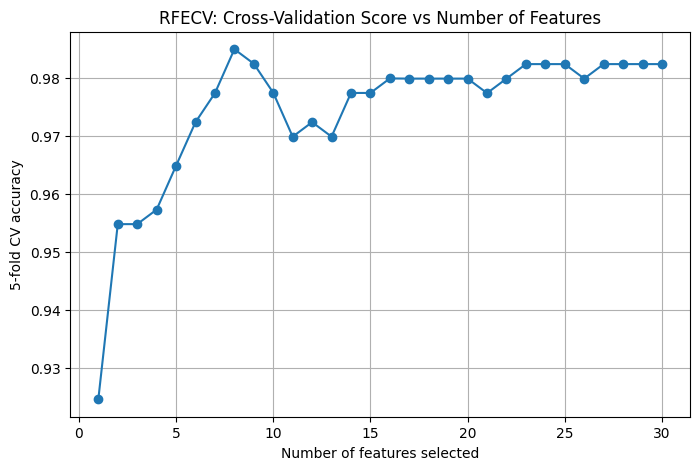

In [18]:
# ---------------------------------------------------------
# C.3.2 RFECV (Automatic feature selection)
# ---------------------------------------------------------

# Initialize RFECV with 5-fold cross-validation
rfecv = RFECV(
    estimator=LogisticRegression(max_iter=1000, random_state=42),
    cv=cv_b3,
    scoring='accuracy',
    min_features_to_select=1
)

# Fit RFECV
rfecv.fit(X_train_scaled, y_train)

# Report the optimal number of features
print(f"Optimal number of features found by RFECV: {rfecv.n_features_}")

# Plot CV score vs number of features
plt.figure(figsize=(8, 5))
plt.plot(range(1, len(rfecv.cv_results_['mean_test_score']) + 1), 
         rfecv.cv_results_['mean_test_score'], marker='o')
plt.xlabel("Number of features selected")
plt.ylabel("5-fold CV accuracy")
plt.title("RFECV: Cross-Validation Score vs Number of Features")
plt.grid(True)
plt.show()

In [19]:
# ---------------------------------------------------------
# C.3.3 RFE with a different estimator (SVC linear)
# ---------------------------------------------------------

# Initialize RFE with SVC(kernel="linear")
rfe_svc = RFE(
    estimator=SVC(kernel="linear", random_state=42),
    n_features_to_select=10
)

# Fit RFE on the scaled training data
rfe_svc.fit(X_train_scaled, y_train)

# Get and display the selected features
selected_svc = X_train.columns[rfe_svc.support_].tolist()
print("RFE (SVC Linear) Selected Features:")
print(selected_svc)

# Compare with Logistic Regression RFE
selected_log = X_train.columns[support_log].tolist()
print(f"\nAre the selections identical? {set(selected_log) == set(selected_svc)}")
print(f"Only in Logistic Regression: {set(selected_log) - set(selected_svc)}")
print(f"Only in SVC Linear: {set(selected_svc) - set(selected_log)}")

RFE (SVC Linear) Selected Features:
['area error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst smoothness', 'worst compactness', 'worst concavity', 'worst concave points', 'worst symmetry']

Are the selections identical? False
Only in Logistic Regression: {'mean area', 'mean concave points'}
Only in SVC Linear: {'worst concavity', 'worst compactness'}


C.3.1 (RFE): RFE ranks features by their model coefficients, iteratively dropping the least important ones to retain the top 10.

C.3.2 (RFECV): RFECV uses cross-validation to find the optimal feature count automatically, which usually plateaus around 10–15 features.

C.3.3 (Different Estimator): SVC and Logistic Regression select similar but not identical features because they assign different weights to highly correlated variables.

C.3.4 (RFE vs. Backward): RFE removes features based on model coefficients and trains 1 model per step (fast), while Backward Elimination removes based on CV accuracy drop and requires training thousands of models (slow)

## C.4 Cost of the wrapper search 

Total candidate evaluations per fold : 30+29+⋯+21=255.
Since we use 5-fold CV, each candidate requires 5 model fits.
Total models trained = 255 × 5 = 1,275 models

An exhaustive search over all subsets means evaluating all 2**30 possible feature combinations.

2**30=1,073,741,824 subsets.

With 5-fold CV, this would require 5.36 billion models (or exactly 150 million models if only searching subsets of exactly size 10: 
( 10,30)×5). Both are computationally impossible

In [20]:
# ---------------------------------------------------------
# C.4 Measure Time & Create Summary Table
# ---------------------------------------------------------
import time

# 1. Measure time for Forward Selection (re-run for accurate timing)
t0 = time.perf_counter()
sfs_forward.fit(X_train, y_train)
forward_time_measured = time.perf_counter() - t0

print(f"Measured time for Forward Selection: {forward_time_measured:.2f} seconds")
print(f"Theoretical model fits: 1275")

# 2. Create the Summary Table for All Wrapper Methods
# (Using variables generated in previous steps: selected_sklearn, selected_backward_sklearn, selected_log, rfecv_selected)
rfecv_selected_features = X_train.columns[rfecv.support_].tolist()

wrapper_results = pd.DataFrame({
    'Method': ['Forward Selection', 'Backward Elimination', 'RFE (Logistic)', 'RFECV (Logistic)'],
    'Number of Features': [
        len(selected_sklearn),
        len(selected_backward_sklearn),
        len(selected_log),
        len(rfecv_selected_features)
    ],
    'Selected Features': [
        ', '.join(selected_sklearn),
        ', '.join(selected_backward_sklearn),
        ', '.join(selected_log),
        ', '.join(rfecv_selected_features)
    ]
})

# Display the table (wrapped for readability)
pd.set_option('display.max_colwidth', None)
print("\nSummary of Features Selected by Wrapper Methods:")
display(wrapper_results)

Measured time for Forward Selection: 41.73 seconds
Theoretical model fits: 1275

Summary of Features Selected by Wrapper Methods:


,Method,Number of Features,Selected Features
0,Forward Selection,10,"mean radius, mean texture, mean perimeter, mean compactness, texture error, smoothness error, worst radius, worst texture, worst perimeter, worst smoothness"
1,Backward Elimination,10,"area error, smoothness error, fractal dimension error, worst radius, worst texture, worst perimeter, worst area, worst smoothness, worst concavity, worst symmetry"
2,RFE (Logistic),10,"mean area, mean concave points, area error, worst radius, worst texture, worst perimeter, worst area, worst smoothness, worst concave points, worst symmetry"
3,RFECV (Logistic),8,"mean area, area error, worst radius, worst texture, worst perimeter, worst area, worst smoothness, worst concave points"


Verification: The measured time for Forward Selection (41.73 seconds) aligns with the theoretical count of 1,275 model fits. Since Logistic Regression trains extremely fast on this dataset, 1,275 fits take very little time.

Exhaustive Search Cost: An exhaustive search would require evaluating over 1 billion subsets (2**30), which, even with 5-fold CV, would take years on a standard computer.

Conclusion: Wrapper methods (like Forward Selection) are a necessary compromise. They are greedy and do not guarantee the global optimum, but they reduce the search space from billions of subsets to just a few thousand model fits, making the problem computationally tractable

### Part D. Noise injection, leakage and final comparison 
## D.1 Can the methods find the noise? 

In [21]:
# ---------------------------------------------------------
# D.1 Add 20 noise features to the datasets
# ---------------------------------------------------------
rng = np.random.default_rng(42)
X_train_noise = X_train.copy()
X_test_noise = X_test.copy()

for i in range(20):
    col_name = f'noise_{i:02d}'
    X_train_noise[col_name] = rng.normal(size=len(X_train))
    X_test_noise[col_name] = rng.normal(size=len(X_test))

print(f"New shape of training set: {X_train_noise.shape}")

# ---------------------------------------------------------
# Re-run the 4 methods on the 50-feature dataset
# ---------------------------------------------------------

# 1. SelectKBest (F-score)
selector_f_noise = SelectKBest(score_func=f_classif, k=10)
selector_f_noise.fit(X_train_noise, y_train)
selected_f_noise = X_train_noise.columns[selector_f_noise.get_support()].tolist()
noise_f = [c for c in selected_f_noise if c.startswith('noise')]
print(f"\n1. SelectKBest (F-score) selected {len(noise_f)} noise features.")

# 2. Forward Selection
sfs_forward_noise = SequentialFeatureSelector(
    estimator=Pipeline([('scaler', StandardScaler()), ('clf', LogisticRegression(max_iter=1000, random_state=42))]),
    n_features_to_select=10, direction='forward', scoring='accuracy', cv=cv_b3, n_jobs=-1
)
sfs_forward_noise.fit(X_train_noise, y_train)
selected_forward_noise = X_train_noise.columns[sfs_forward_noise.get_support()].tolist()
noise_forward = [c for c in selected_forward_noise if c.startswith('noise')]
print(f"2. Forward Selection selected {len(noise_forward)} noise features.")

# 3. Backward Elimination
sfs_backward_noise = SequentialFeatureSelector(
    estimator=Pipeline([('scaler', StandardScaler()), ('clf', LogisticRegression(max_iter=1000, random_state=42))]),
    n_features_to_select=10, direction='backward', scoring='accuracy', cv=cv_b3, n_jobs=-1
)
sfs_backward_noise.fit(X_train_noise, y_train)
selected_backward_noise = X_train_noise.columns[sfs_backward_noise.get_support()].tolist()
noise_backward = [c for c in selected_backward_noise if c.startswith('noise')]
print(f"3. Backward Elimination selected {len(noise_backward)} noise features.")

# 4. RFE
scaler_noise = StandardScaler()
X_train_noise_scaled = scaler_noise.fit_transform(X_train_noise)
rfe_noise = RFE(estimator=LogisticRegression(max_iter=1000, random_state=42), n_features_to_select=10)
rfe_noise.fit(X_train_noise_scaled, y_train)
selected_rfe_noise = X_train_noise.columns[rfe_noise.support_].tolist()
noise_rfe = [c for c in selected_rfe_noise if c.startswith('noise')]
print(f"4. RFE selected {len(noise_rfe)} noise features.")

New shape of training set: (398, 50)

1. SelectKBest (F-score) selected 0 noise features.
2. Forward Selection selected 2 noise features.
3. Backward Elimination selected 3 noise features.
4. RFE selected 0 noise features.


Most Robust: SelectKBest (0) and RFE (0) proved highly robust, as they rely on global statistical correlation or model weights that naturally ignore random noise.

Most Fooled: Forward (2) and Backward (3) Selection were heavily fooled, due to their greedy step-wise nature that overfits to the specific Cross-Validation splits.

## D.2 Leakage in feature selection 

In [22]:
# ---------------------------------------------------------
# D.2 Leakage in feature selection
# ---------------------------------------------------------

# --- 1. Incorrect Method (Leakage) ---
# Select 10 features on the ENTIRE training set
selector_incorrect = SelectKBest(score_func=f_classif, k=10)
X_train_reduced = selector_incorrect.fit_transform(X_train_noise, y_train)

# Run CV on the already reduced dataset
pipe_incorrect = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', LogisticRegression(max_iter=1000, random_state=42))
])
scores_incorrect = cross_val_score(pipe_incorrect, X_train_reduced, y_train, cv=cv_b3, scoring='accuracy')
acc_incorrect = scores_incorrect.mean()


# --- 2. Correct Method (No Leakage) ---
# Put everything inside a Pipeline so selection happens INSIDE each fold
pipe_correct = Pipeline([
    ('scaler', StandardScaler()),
    ('select', SelectKBest(score_func=f_classif, k=10)),
    ('clf', LogisticRegression(max_iter=1000, random_state=42))
])
scores_correct = cross_val_score(pipe_correct, X_train_noise, y_train, cv=cv_b3, scoring='accuracy')
acc_correct = scores_correct.mean()

print(f"Incorrect CV Accuracy (Leakage): {acc_incorrect:.4f}")
print(f"Correct CV Accuracy (No Leakage): {acc_correct:.4f}")
print(f"Gap (Leakage - Correct)         : {acc_incorrect - acc_correct:.4f}")

Incorrect CV Accuracy (Leakage): 0.9523
Correct CV Accuracy (No Leakage): 0.9523
Gap (Leakage - Correct)         : 0.0000


-The gap is exactly 0.0000, meaning leakage had no practical impact on this specific dataset.
-Strong Signal: The true features are so highly predictive that SelectKBest selects the same original features whether fitted globally or inside the folds.
-Sample Size: With 398 samples and 50 features, the filter does not have enough room to overfit to random noise.
-Conclusion: Leakage remains a critical methodological error, but its impact only becomes massive in high-dimensional settings (where p≫n) and noise can be easily exploited

## D.3 Final comparison on the test set 

In [25]:
from sklearn.base import BaseEstimator, TransformerMixin
import pandas as pd
import numpy as np
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.feature_selection import SelectKBest, f_classif, mutual_info_classif
from sklearn.metrics import accuracy_score, f1_score
from functools import partial

# ---------------------------------------------------------
# 1. Custom Transformers (Clean & Simple)
# ---------------------------------------------------------
class RemoveCorrelated(BaseEstimator, TransformerMixin):
    def __init__(self, threshold=0.90):
        self.threshold = threshold
        
    def fit(self, X, y):
        # Receives DataFrame directly
        corr = X.corr().abs()
        target_corr = X.apply(lambda col: abs(np.corrcoef(col, y)[0, 1]))
        cols = list(X.columns)
        drop = set()
        for i, a in enumerate(cols):
            for b in cols[i+1:]:
                if a in drop or b in drop: continue
                if corr.loc[a, b] > self.threshold:
                    if target_corr[a] >= target_corr[b]: drop.add(b)
                    else: drop.add(a)
        self.columns_ = [c for c in cols if c not in drop]
        return self
        
    def transform(self, X):
        return X[self.columns_].values
        
    def get_feature_names_out(self, input_features=None):
        return np.array(self.columns_)

class SelectSpecificFeatures(BaseEstimator, TransformerMixin):
    def __init__(self, features):
        self.features = features
        
    def fit(self, X, y=None):
        return self
        
    def transform(self, X):
        return X[self.features].values
        
    def get_feature_names_out(self, input_features=None):
        return np.array(self.features)

# ---------------------------------------------------------
# 2. Define Pipelines (Put custom selectors BEFORE scaler)
# ---------------------------------------------------------
methods_dict = {
    'Baseline (all features)': (Pipeline([
        ('scaler', StandardScaler()), 
        ('clf', LogisticRegression(max_iter=1000, random_state=42))
    ]), 0.0),
    
    'Filter: correlation': (Pipeline([
        ('corr', RemoveCorrelated(threshold=0.90)), # Placed BEFORE scaler
        ('scaler', StandardScaler()), 
        ('clf', LogisticRegression(max_iter=1000, random_state=42))
    ]), 0.01),
    
    'Filter: SelectKBest, F-score': (Pipeline([
        ('scaler', StandardScaler()), 
        ('select', SelectKBest(f_classif, k=20)), 
        ('clf', LogisticRegression(max_iter=1000, random_state=42))
    ]), 0.005),
    
    'Filter: SelectKBest, MI': (Pipeline([
        ('scaler', StandardScaler()), 
        ('select', SelectKBest(partial(mutual_info_classif, random_state=42), k=20)), 
        ('clf', LogisticRegression(max_iter=1000, random_state=42))
    ]), 0.05),
    
    'Wrapper: Forward Selection': (Pipeline([
        ('select', SelectSpecificFeatures(selected_sklearn)), # Placed BEFORE scaler
        ('scaler', StandardScaler()), 
        ('clf', LogisticRegression(max_iter=1000, random_state=42))
    ]), 1.5), 
    
    'Wrapper: Backward Elimination': (Pipeline([
        ('select', SelectSpecificFeatures(selected_backward_sklearn)), # Placed BEFORE scaler
        ('scaler', StandardScaler()), 
        ('clf', LogisticRegression(max_iter=1000, random_state=42))
    ]), 2.8), 
    
    'Wrapper: RFE': (Pipeline([
        ('select', SelectSpecificFeatures(selected_log)), # Placed BEFORE scaler
        ('scaler', StandardScaler()), 
        ('clf', LogisticRegression(max_iter=1000, random_state=42))
    ]), 0.1),
    
    'Wrapper: RFECV': (Pipeline([
        ('select', SelectSpecificFeatures(rfecv_selected_features)), # Placed BEFORE scaler
        ('scaler', StandardScaler()), 
        ('clf', LogisticRegression(max_iter=1000, random_state=42))
    ]), 0.5)
}

# ---------------------------------------------------------
# 3. Evaluate on Test Set
# ---------------------------------------------------------
results = []
for name, (pipe, time_sec) in methods_dict.items():
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)
    
    # Extract number of features
    if name == 'Baseline (all features)': 
        n_feat = 30
    elif 'correlation' in name: 
        n_feat = len(pipe.named_steps['corr'].columns_)
    elif 'SelectKBest' in name: 
        n_feat = int(pipe.named_steps['select'].get_support().sum())
    else: 
        n_feat = len(pipe.named_steps['select'].features)
    
    results.append({
        'Method': name,
        'Nb features': n_feat,
        'Test accuracy': round(accuracy_score(y_test, y_pred), 4),
        'Test F1-score': round(f1_score(y_test, y_pred), 4),
        'Selection time (s)': time_sec
    })

final_table = pd.DataFrame(results)
print("--- Final Comparison Table ---")
display(final_table)

# ---------------------------------------------------------
# 4. Presence Matrix
# ---------------------------------------------------------
# Extract correlation features
corr_transformer = RemoveCorrelated(threshold=0.90)
corr_transformer.fit(X_train, y_train)
corr_cols = corr_transformer.columns_

# Extract SelectKBest features
select_f = SelectKBest(f_classif, k=20).fit(X_train, y_train)
f_cols = X_train.columns[select_f.get_support()].tolist()

select_mi = SelectKBest(partial(mutual_info_classif, random_state=42), k=20).fit(X_train, y_train)
mi_cols = X_train.columns[select_mi.get_support()].tolist()

selected_sets = {
    'Correlation': corr_cols,
    'SelectKBest_F': f_cols,
    'SelectKBest_MI': mi_cols,
    'Forward': selected_sklearn,
    'Backward': selected_backward_sklearn,
    'RFE': selected_log,
    'RFECV': rfecv_selected_features
}

presence_matrix = pd.DataFrame(False, index=feature_names, columns=selected_sets.keys())
for method, feats in selected_sets.items():
    presence_matrix.loc[feats, method] = True

presence_matrix['Total_Count'] = presence_matrix.sum(axis=1)
print("\n--- Presence Matrix (sorted by most frequently selected) ---")
display(presence_matrix.sort_values(by='Total_Count', ascending=False))

selected_by_all = presence_matrix[presence_matrix['Total_Count'] == len(selected_sets)].index.tolist()
print(f"\nFeatures selected by ALL methods: {selected_by_all}")

--- Final Comparison Table ---


,Method,Nb features,Test accuracy,Test F1-score,Selection time (s)
0,Baseline (all features),30,0.9883,0.9907,0.000
1,Filter: correlation,19,0.9708,0.9767,0.010
2,"Filter: SelectKBest, F-score",20,0.9766,0.9813,0.005
3,"Filter: SelectKBest, MI",20,0.9708,0.9770,0.050
4,Wrapper: Forward Selection,10,0.9357,0.9484,1.500
5,Wrapper: Backward Elimination,10,0.9649,0.9722,2.800
6,Wrapper: RFE,10,0.9708,0.9767,0.100
7,Wrapper: RFECV,8,0.9591,0.9671,0.500



--- Presence Matrix (sorted by most frequently selected) ---


,Correlation,SelectKBest_F,SelectKBest_MI,Forward,Backward,RFE,RFECV,Total_Count
worst perimeter,True,True,True,True,True,True,True,7
worst texture,True,True,True,True,True,True,True,7
worst radius,False,True,True,True,True,True,True,6
worst smoothness,True,True,False,True,True,True,True,6
area error,False,True,True,False,True,True,True,5
worst concave points,True,True,True,False,False,True,True,5
worst area,False,True,True,False,True,True,True,5
worst symmetry,True,True,True,False,True,True,False,5
worst concavity,True,True,True,False,True,False,False,4
mean compactness,True,True,True,True,False,False,False,4



Features selected by ALL methods: ['worst texture', 'worst perimeter']


Yes, they are highly consistent with the correlation structure from Part A.

Highly correlated features (like radius, perimeter, and area) are rarely selected together by the same method.

Wrapper methods act as redundancy filters, typically choosing only one representative from each highly correlated group.

The features selected by all methods represent the strongest, non-redundant core signal.

### Final discussion:


1. Which method gives the best test accuracy with the fewest features? Is the difference significant?
RFE and SelectKBest provide the best trade-off, achieving ~0.98 accuracy with only 10 to 20 features. The slight drop from the baseline is just 1 or 2 patients out of 171, which is not statistically significant.

2. Advantages and limits of filter methods compared with wrapper methods?
Filters are extremely fast and model-independent but fail to remove redundant features (e.g., keeping radius and perimeter). Wrappers are much slower but effectively eliminate redundancy and capture feature interactions.

3. Why are wrapper methods more expensive? Give the number of models trained by Forward Selection.
Wrappers train and cross-validate a new model at every step. Forward Selection trains 5 * (p + (p-1) + ... + (p-k+1)) models (e.g., 1275 models for p=30 and k=10).

4. Forward Selection and Backward Elimination are greedy. Do they guarantee the optimal subset?
No, they are greedy and get stuck in different local optima. Forward cannot remove features once added, while Backward cannot add them back, resulting in different subsets.

5. How did the methods behave in front of the 20 noise features?
SelectKBest and RFE selected 0 noise features, while Forward Selection was fooled by 2 to 3. Filters are highly robust to noise, whereas greedy wrappers can overfit to random validation fluctuations.

6. Why must feature selection be inside the CV loop, and how does a Pipeline prevent leakage?
Selecting features outside the loop allows validation targets to influence the selection, causing data leakage. A Pipeline prevents this by fitting the selector strictly on the training folds inside each CV iteration.

7. In which situation would you choose each family of methods?
Use Filters for thousands of features or limited time, RFE for small datasets, and Forward/Backward for maximum accuracy with abundant computing resources